###**QUESTION 1**

In [2]:
import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk import FreqDist

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

text = """
Nature is the ultimate sanctuary, offering a quiet escape from the noise and speed of modern life. It speaks a silent language of renewal, where the simple rustle of green leaves, the steady flow of rivers, and the warmth of sunlight work together to restore our energy
"""

print("Original Text:\n", text)

#Convert text to lowercase and remove punctuation
cleaned_text = re.sub(r'[^\w\s]', '', text.lower())

print("\nCleaned Text:\n", cleaned_text)

#Tokenize into words and sentences
words = word_tokenize(cleaned_text)
sentences = sent_tokenize(text)

print("\nWord Tokens:\n", words)
print("\nSentence Tokens:\n", sentences)

#Compare split() and word_tokenize()
print("\nUsing split():\n", cleaned_text.split())
print("\nUsing word_tokenize():\n", word_tokenize(text))

#Remove stopwords
stop_words = set(stopwords.words('english'))

filtered_words = [
    word for word in words
    if word.isalpha() and word not in stop_words
]

print("\nWords after Stopword Removal:\n", filtered_words)

#Display word frequency distribution
freq_dist = FreqDist(filtered_words)

print("\nWord Frequency Distribution:")
for word, frequency in freq_dist.most_common():
    print(word, ":", frequency)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


Original Text:
 
Nature is the ultimate sanctuary, offering a quiet escape from the noise and speed of modern life. It speaks a silent language of renewal, where the simple rustle of green leaves, the steady flow of rivers, and the warmth of sunlight work together to restore our energy. Beyond its visual beauty, the natural world serves as a gentle reminder of balance and patience, showing us that every season has its purpose.


Cleaned Text:
 
nature is the ultimate sanctuary offering a quiet escape from the noise and speed of modern life it speaks a silent language of renewal where the simple rustle of green leaves the steady flow of rivers and the warmth of sunlight work together to restore our energy beyond its visual beauty the natural world serves as a gentle reminder of balance and patience showing us that every season has its purpose


Word Tokens:
 ['nature', 'is', 'the', 'ultimate', 'sanctuary', 'offering', 'a', 'quiet', 'escape', 'from', 'the', 'noise', 'and', 'speed', 'of',

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


###**QUESTION 2**

In [4]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

# Download required resources
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

# Use the same paragraph as Q1
text = """
Nature is the ultimate sanctuary, offering a quiet escape from the noise and speed of modern life. It speaks a silent language of renewal, where the simple rustle of green leaves, the steady flow of rivers, and the warmth of sunlight work together to restore our energy.
"""

#Extract alphabetic words
words = re.findall(r'\b[a-zA-Z]+\b', text.lower())

print("Alphabetic Words:\n", words)

#Remove stopwords
stop_words = set(stopwords.words('english'))

filtered_words = [
    word for word in words
    if word not in stop_words
]

print("\nWords after Stopword Removal:\n", filtered_words)

#Perform stemming
stemmer = PorterStemmer()

stemmed_words = [
    stemmer.stem(word)
    for word in filtered_words
]

print("\nStemmed Words:\n", stemmed_words)

#Perform lemmatization
lemmatizer = WordNetLemmatizer()

lemmatized_words = [
    lemmatizer.lemmatize(word, pos='v')
    for word in filtered_words
]

print("\nLemmatized Words:\n", lemmatized_words)

#Compare outputs
print("\nComparison:")
for original, stem, lemma in zip(
    filtered_words, stemmed_words, lemmatized_words
):
    print(
        f"Original: {original:15} "
        f"Stem: {stem:12} Lemma: {lemma}"
    )

Alphabetic Words:
 ['nature', 'is', 'the', 'ultimate', 'sanctuary', 'offering', 'a', 'quiet', 'escape', 'from', 'the', 'noise', 'and', 'speed', 'of', 'modern', 'life', 'it', 'speaks', 'a', 'silent', 'language', 'of', 'renewal', 'where', 'the', 'simple', 'rustle', 'of', 'green', 'leaves', 'the', 'steady', 'flow', 'of', 'rivers', 'and', 'the', 'warmth', 'of', 'sunlight', 'work', 'together', 'to', 'restore', 'our', 'energy']

Words after Stopword Removal:
 ['nature', 'ultimate', 'sanctuary', 'offering', 'quiet', 'escape', 'noise', 'speed', 'modern', 'life', 'speaks', 'silent', 'language', 'renewal', 'simple', 'rustle', 'green', 'leaves', 'steady', 'flow', 'rivers', 'warmth', 'sunlight', 'work', 'together', 'restore', 'energy']

Stemmed Words:
 ['natur', 'ultim', 'sanctuari', 'offer', 'quiet', 'escap', 'nois', 'speed', 'modern', 'life', 'speak', 'silent', 'languag', 'renew', 'simpl', 'rustl', 'green', 'leav', 'steadi', 'flow', 'river', 'warmth', 'sunlight', 'work', 'togeth', 'restor', 'ene

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


###**QUESTION 3**

In [5]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer

# Create three short texts
documents = [
    "Artificial intelligence helps machines learn and make predictions.",
    "Machine learning analyzes data to identify useful patterns.",
    "Blockchain technology provides secure and transparent transactions."
]

# Bag of Words representation
count_vectorizer = CountVectorizer()

bow_matrix = count_vectorizer.fit_transform(documents)

print("Vocabulary:")
print(count_vectorizer.get_feature_names_out())

print("\nBag of Words Matrix:")
print(bow_matrix.toarray())

# TF-IDF representation
tfidf_vectorizer = TfidfVectorizer()

tfidf_matrix = tfidf_vectorizer.fit_transform(documents)

feature_names = tfidf_vectorizer.get_feature_names_out()

print("\nTF-IDF Matrix:")
print(tfidf_matrix.toarray())

# Find the top 3 keywords for each document
print("\nTop 3 TF-IDF Keywords:")

for i, document in enumerate(documents):
    scores = tfidf_matrix[i].toarray().flatten()

    top_indices = scores.argsort()[-3:][::-1]

    print(f"\nDocument {i + 1}: {document}")

    for index in top_indices:
        print(
            feature_names[index],
            ":", round(scores[index], 4)
        )

Vocabulary:
['analyzes' 'and' 'artificial' 'blockchain' 'data' 'helps' 'identify'
 'intelligence' 'learn' 'learning' 'machine' 'machines' 'make' 'patterns'
 'predictions' 'provides' 'secure' 'technology' 'to' 'transactions'
 'transparent' 'useful']

Bag of Words Matrix:
[[0 1 1 0 0 1 0 1 1 0 0 1 1 0 1 0 0 0 0 0 0 0]
 [1 0 0 0 1 0 1 0 0 1 1 0 0 1 0 0 0 0 1 0 0 1]
 [0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 1 1 1 0 1 1 0]]

TF-IDF Matrix:
[[0.         0.27626457 0.36325471 0.         0.         0.36325471
  0.         0.36325471 0.36325471 0.         0.         0.36325471
  0.36325471 0.         0.36325471 0.         0.         0.
  0.         0.         0.         0.        ]
 [0.35355339 0.         0.         0.         0.35355339 0.
  0.35355339 0.         0.         0.35355339 0.35355339 0.
  0.         0.35355339 0.         0.         0.         0.
  0.35355339 0.         0.         0.35355339]
 [0.         0.29651988 0.         0.38988801 0.         0.
  0.         0.         0.         0.    

###**QUESTION 4**

In [6]:
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Step 1: Write two texts about different technologies
text1 = """
Artificial intelligence enables computers to learn from data.
Machine learning helps systems identify patterns and make predictions.
AI is widely used in healthcare, education, and automation.
"""

text2 = """
Blockchain stores information in distributed digital records.
Cryptographic techniques help protect transactions and data integrity.
Blockchain is widely used in finance and secure digital systems.
"""

# Preprocess and tokenize
def preprocess(text):
    text = text.lower()
    words = re.findall(r'\b[a-zA-Z]+\b', text)
    return words

words1 = preprocess(text1)
words2 = preprocess(text2)

print("Tokens in Text 1:\n", words1)
print("\nTokens in Text 2:\n", words2)

# Step 3: Calculate Jaccard similarity
set1 = set(words1)
set2 = set(words2)

intersection = set1.intersection(set2)
union = set1.union(set2)

if len(union) > 0:
    jaccard_similarity = len(intersection) / len(union)
else:
    jaccard_similarity = 0.0

print("\nCommon Words:", intersection)
print("Jaccard Similarity:", round(jaccard_similarity, 4))

# Calculate cosine similarity using TF-IDF
texts = [text1, text2]

vectorizer = TfidfVectorizer()

tfidf_matrix = vectorizer.fit_transform(texts)

cosine_score = cosine_similarity(
    tfidf_matrix[0:1],
    tfidf_matrix[1:2]
)[0][0]

print("Cosine Similarity:", round(cosine_score, 4))

# Compare the results
print("\nComparison:")

if jaccard_similarity > cosine_score:
    print("Jaccard similarity is higher for these texts.")
elif cosine_score > jaccard_similarity:
    print("Cosine similarity is higher for these texts.")
else:
    print("Both similarity scores are equal.")

print(
    "Jaccard measures word-set overlap, while cosine similarity "
    "compares the TF-IDF representations."
)

Tokens in Text 1:
 ['artificial', 'intelligence', 'enables', 'computers', 'to', 'learn', 'from', 'data', 'machine', 'learning', 'helps', 'systems', 'identify', 'patterns', 'and', 'make', 'predictions', 'ai', 'is', 'widely', 'used', 'in', 'healthcare', 'education', 'and', 'automation']

Tokens in Text 2:
 ['blockchain', 'stores', 'information', 'in', 'distributed', 'digital', 'records', 'cryptographic', 'techniques', 'help', 'protect', 'transactions', 'and', 'data', 'integrity', 'blockchain', 'is', 'widely', 'used', 'in', 'finance', 'and', 'secure', 'digital', 'systems']

Common Words: {'is', 'systems', 'used', 'widely', 'in', 'data', 'and'}
Jaccard Similarity: 0.1795
Cosine Similarity: 0.2249

Comparison:
Cosine similarity is higher for these texts.
Jaccard measures word-set overlap, while cosine similarity compares the TF-IDF representations.


###**QUESTION 5**

Sentiment Analysis Results:

Review 1: This phone has an excellent camera and amazing battery life.
Polarity: 0.8
Subjectivity: 0.95
Sentiment: Positive

Review 2: The product is terrible and its performance is disappointing.
Polarity: -0.8
Subjectivity: 0.85
Sentiment: Negative

Review 3: The phone is average and works as expected.
Polarity: -0.125
Subjectivity: 0.4
Sentiment: Negative

Review 4: I love this phone because it is fast and easy to use.
Polarity: 0.3778
Subjectivity: 0.6778
Sentiment: Positive

Review 5: The battery drains quickly and the service is poor.
Polarity: -0.0333
Subjectivity: 0.55
Sentiment: Negative



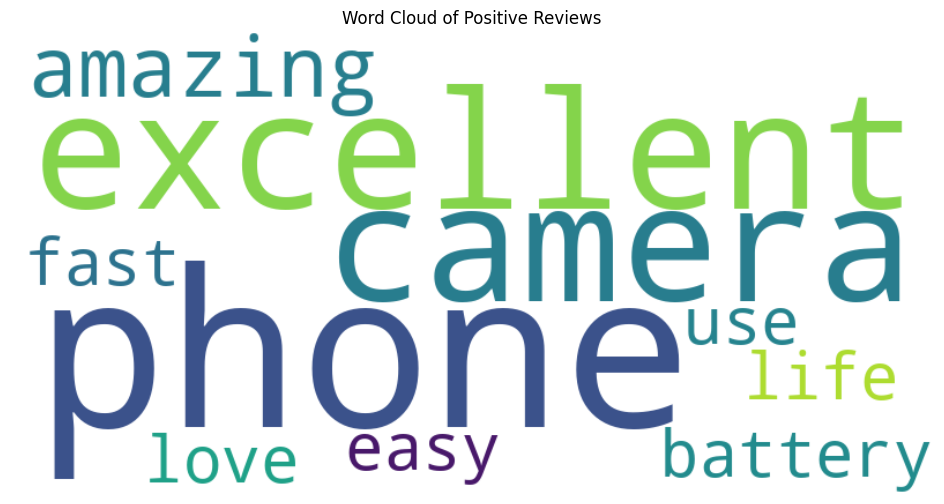

In [7]:
from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Write product reviews
reviews = [
    "This phone has an excellent camera and amazing battery life.",
    "The product is terrible and its performance is disappointing.",
    "The phone is average and works as expected.",
    "I love this phone because it is fast and easy to use.",
    "The battery drains quickly and the service is poor."
]

positive_reviews = []

# Calculate polarity and subjectivity and Classify each review
print("Sentiment Analysis Results:\n")

for i, review in enumerate(reviews, start=1):
    analysis = TextBlob(review).sentiment

    polarity = analysis.polarity
    subjectivity = analysis.subjectivity

    if polarity > 0:
        sentiment = "Positive"
        positive_reviews.append(review)
    elif polarity < 0:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print(f"Review {i}: {review}")
    print("Polarity:", round(polarity, 4))
    print("Subjectivity:", round(subjectivity, 4))
    print("Sentiment:", sentiment)
    print()

# Create a word cloud from positive reviews
if positive_reviews:
    positive_text = " ".join(positive_reviews)

    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color="white"
    ).generate(positive_text)

    plt.figure(figsize=(12, 6))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Word Cloud of Positive Reviews")
    plt.show()
else:
    print("No positive reviews found.")

###**QUESTION 6**

In [9]:
import numpy as np
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

# Prepare training text
text = """
Artificial intelligence is changing the modern world.
Machine learning allows computers to learn from data and
identify useful patterns. Deep learning uses neural networks
to solve complex problems. Artificial intelligence is used
in healthcare, education, finance, and transportation.
Machine learning helps doctors analyze medical data.
It also helps businesses make better decisions.
Neural networks learn patterns from training examples.
Computers use these patterns to make predictions.
Artificial intelligence can automate repetitive tasks.
Machine learning continues to improve with more data.
Deep learning can recognize images and understand language.
Researchers develop intelligent systems to solve real problems.
Artificial intelligence is becoming important in everyday life.
"""

np.random.seed(42)
tf.random.set_seed(42)

# Tokenize the text

tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])

total_words = len(tokenizer.word_index) + 1

print("Vocabulary Size:", total_words)

# Create input sequences

input_sequences = []

for line in text.lower().split('\n'):
    line = line.strip()

    if not line:
        continue

    sequence = tokenizer.texts_to_sequences([line])[0]

    for i in range(1, len(sequence)):
        input_sequences.append(sequence[:i + 1])


if not input_sequences:
    raise ValueError("No input sequences were generated.")


# Pad sequences to equal length

max_sequence_len = max(len(seq) for seq in input_sequences)

input_sequences = pad_sequences(
    input_sequences,
    maxlen=max_sequence_len,
    padding='pre'
)

# Separate input features and target words

X = input_sequences[:, :-1]
y = input_sequences[:, -1]

print("Input Shape:", X.shape)
print("Target Shape:", y.shape)


# Build the LSTM model

model = Sequential([
    Embedding(
        input_dim=total_words,
        output_dim=32
    ),
    LSTM(64),
    Dense(total_words, activation='softmax')
])

model.build(input_shape=(None, X.shape[1]))

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("\nModel Summary:")
model.summary()

# Training

print("\nTraining the model...")

history = model.fit(
    X,
    y,
    epochs=150,
    verbose=0
)

print("Model training completed!")

print(
    "Final Training Accuracy:",
    round(history.history['accuracy'][-1], 4)
)

# Generate text using a seed word

def generate_text(seed_text, next_words=20):
    generated_text = seed_text.lower().strip()

    for _ in range(next_words):

        # Convert the current text into integer tokens
        token_list = tokenizer.texts_to_sequences(
            [generated_text]
        )[0]

        if not token_list:
            print("Seed text contains no known vocabulary words.")
            break

        # Keep the input at the required sequence length
        token_list = pad_sequences(
            [token_list],
            maxlen=X.shape[1],
            padding='pre',
            truncating='pre'
        )

        # Predict the next word
        predicted_probabilities = model.predict(
            token_list,
            verbose=0
        )[0]

        predicted_word_index = int(
            np.argmax(predicted_probabilities)
        )

        # Stop if padding is predicted
        if predicted_word_index == 0:
            break

        # Convert predicted index back to a word
        output_word = tokenizer.index_word.get(
            predicted_word_index
        )

        if output_word is None:
            break

        # Append the predicted word
        generated_text += " " + output_word

    return generated_text


seed_word = "artificial"

generated_text = generate_text(
    seed_word,
    next_words=30
)

print("\nSeed Word:", seed_word)
print("\nGenerated Text:\n")
print(generated_text)

Vocabulary Size: 69
Input Shape: (90, 8)
Target Shape: (90,)

Model Summary:


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 8, 32)          │         2,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 69)             │         4,485 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,525 (123.14 KB)

 Trainable params: 31,525 (123.14 KB)

 Non-trainable params: 0 (0.00 B)


Training the model...
Model training completed!
Final Training Accuracy: 0.9444

Seed Word: artificial

Generated Text:

artificial intelligence is changing the modern world world life life life decisions networks examples language language life life life life life life life life language life life life life life life
